<h1 style="font-size:300%">🌼 WILDFLOWER FINDER</h1>

This notebook shows a simplified implementation for a wildflower object detection model. Images are top-down photos of fields and meadows including wildflowers, which the model is supposed to detect and classify. Note that this is an actual case that was addressed by the Lectorate of AI & Data in 2023.

Bas S.H.T. Michielsen, 2026

![banner](https://codeberg.org/Fontys/wildflower_finder/raw/branch/main/BANNER.jpg)

*Image by Stable Diffusion: a robot looking for wildflowers in a meadow*

In [1]:
import IPython, lightning, os, pandas, PIL, platform, random, torch, torchvision, xml

from collections import defaultdict
from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision import transforms
from lightning import LightningDataModule, LightningModule, Trainer
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.callbacks import EarlyStopping

import matplotlib.pyplot as plt

lightning.seed_everything(42)

torch.set_float32_matmul_precision('medium')

image_size = "medium" # options: ["small", "medium", "large"]

data_path = "EWD_subset"

print("Versions: python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| lightning", lightning.__version__)

Seed set to 42


Versions: python 3.14.7 | torch 2.14.0+cpu | torchvision 0.29.0+cpu | lightning 2.6.5


# ⛲ Data Source

The original dataset is the [Eindhoven Wildflower Dataset](https://dataverse.nl/dataset.xhtml?persistentId=doi:10.34894/U4VQJ6) (Schouten G and Michielsen BSHT, 2024) that is published on Dataverse and belongs to the academic publication [Data-centric AI approach for automated wildflower monitoring](https://doi.org/10.1371/journal.pone.0302958) (Schouten G, Michielsen BSHT, Gravendeel B, 2024) and holds a total of 2002 photos with 65571 annotations for 160 species of flowering plants. However, the subset that we use here is a preprocessed version of the original EWD that hold 600 images of 600 annotations (one per image) of 10 species (exactly 60 images per species). The original dataset is open, so feel free to use it in your own work if you want to.

# 🛠️ Data Preprocessing

Note that the original images are 1024x1024 crops from the original dataset, however, for demo purposes we are resizing them to 640x640 here.

In [2]:
# Afbeeldingsgrootte voor een kleine CPU-test
image_size = (320, 320)

# Vooraf getraind objectdetectiemodel
pretrained_model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn(
    weights="DEFAULT"
)

In [3]:
class ObjectDetectionDataset(Dataset):
    def __init__(self, path, image_size):
        self.path = path
        self.image_size = image_size
        self.annotations = [f for f in os.listdir(path) if f.endswith(".xml")]
        names = list(set([o.find("name").text 
            for a in self.annotations 
            for o in xml.etree.ElementTree.parse(os.path.join(self.path, a)).getroot().findall("object")]))
        names.sort()
        self.classes = ["__background__"] + names

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        image = PIL.Image.open(os.path.join(self.path, self.annotations[index].replace(".xml", ".jpg"))).convert("RGB")
        w, h = image.size
        x_scale, y_scale = self.image_size[0] / w, self.image_size[1] / h
        image = transforms.Compose([
            transforms.Resize(self.image_size),
            transforms.ToTensor(),
        ])(image)
        labels, boxes = [], []
        for obj in xml.etree.ElementTree.parse(os.path.join(self.path, self.annotations[index])).getroot().findall("object"):
            labels.append(self.classes.index(obj.find("name").text))
            bbox = obj.find("bndbox")
            xmin = int(bbox.find("xmin").text) * x_scale
            ymin = int(bbox.find("ymin").text) * y_scale
            xmax = int(bbox.find("xmax").text) * x_scale
            ymax = int(bbox.find("ymax").text) * y_scale
            boxes.append([xmin, ymin, xmax, ymax])
        boxes = torch.tensor(boxes, dtype=torch.float32) if boxes else torch.empty((0, 4), dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64) if labels else torch.empty((0,), dtype=torch.int64)
        return image, {"boxes": boxes, "labels": labels}

dataset = ObjectDetectionDataset(data_path, image_size)
print("Created a dataset with", len(dataset), "images of size", dataset.image_size, "and the following classes:")
for c in dataset.classes:
    print(c)

Created a dataset with 600 images of size (320, 320) and the following classes:
__background__
Achillea millefolium
Centaurea cyanus
Centaurea jacea
Hypochaeris radicata
Leucanthemum vulgare
Papaver rhoeas
Plantago lanceolata
Trifolium pratense
Trifolium repens
Vicia cracca


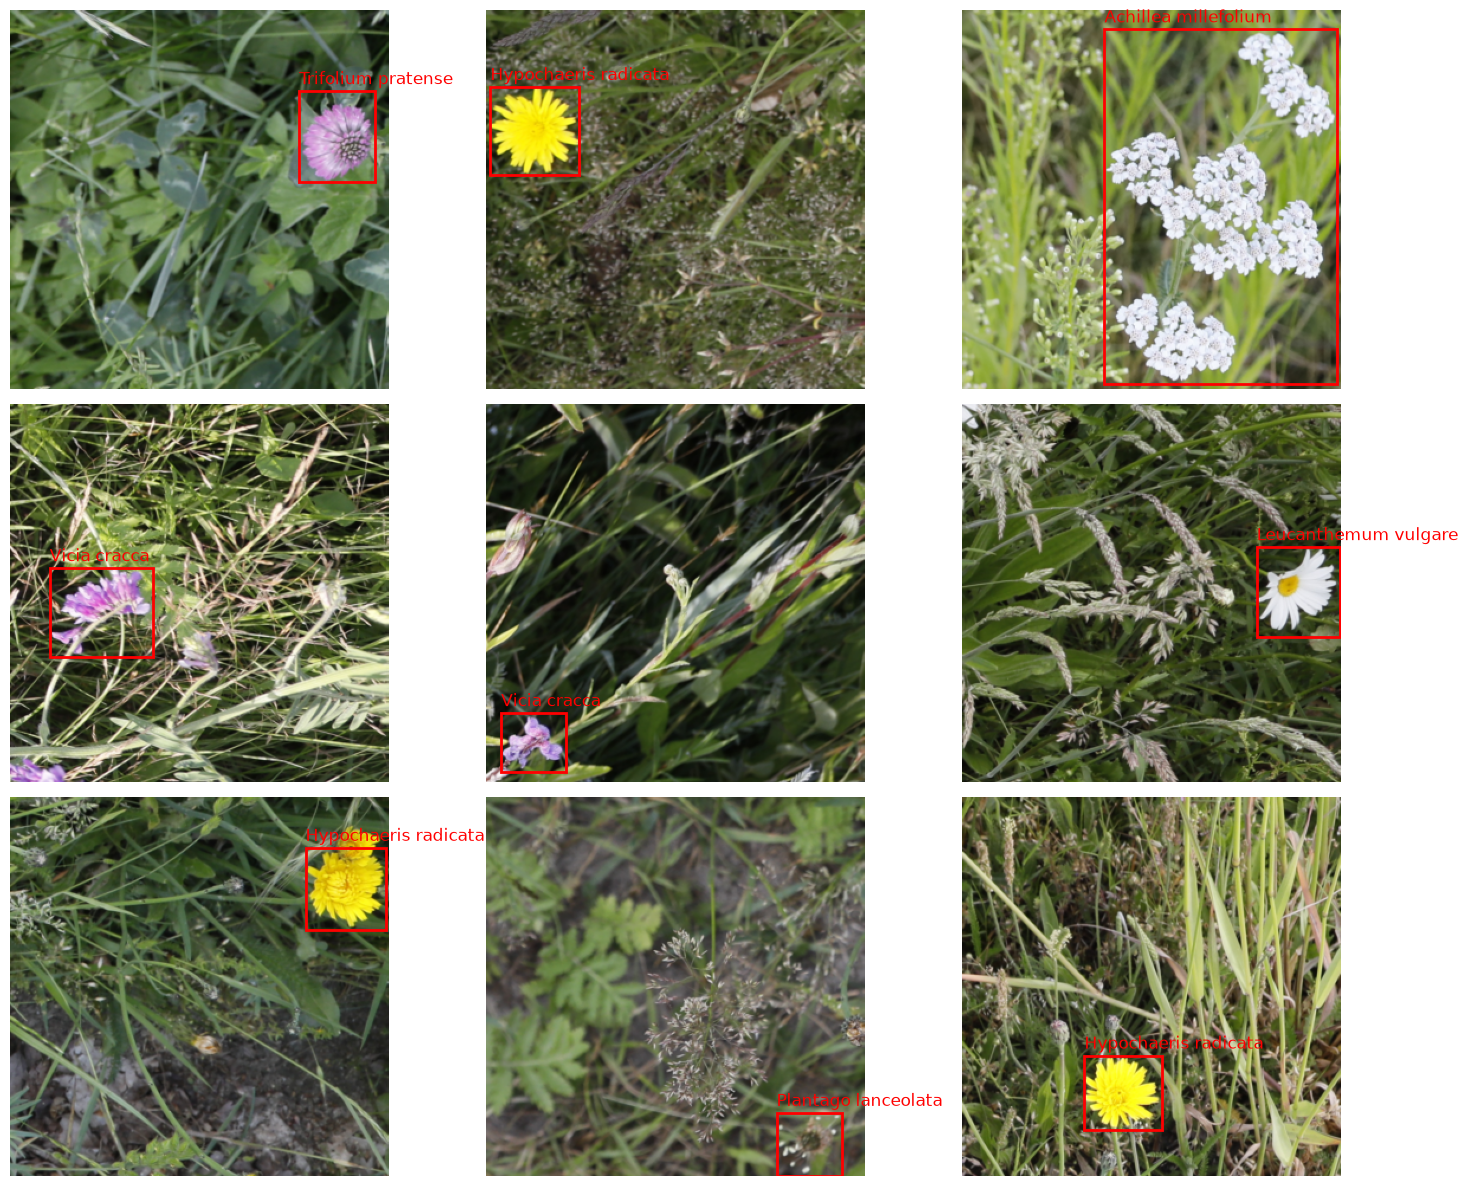

In [4]:
num_images = 9
indices = random.sample(range(len(dataset)), num_images)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for ax, index in zip(axes, indices):
    image, target = dataset[index]
    ax.imshow(transforms.ToPILImage()(image))
    ax.axis("off")
    for box, label in zip(target["boxes"], target["labels"]):
        xmin, ymin, xmax, ymax = box
        rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color='red', linewidth=2)
        ax.add_patch(rect)
        ax.text(xmin, ymin - 6, dataset.classes[label.item()], color='red', fontsize=12)
plt.tight_layout()

This data module ensures that for each of the classes there is an equal number of observations both for the validation dataset as well as the test dataset. We are picking 10 as the size for validation (per class) and 6 for test.

In [5]:
def collate(batch):
    return tuple(zip(*batch))

class DataModule(LightningDataModule):
    def __init__(self, data, val_size, test_size, batch_size=16, num_workers=0):
        super().__init__()
        self.data = data
        self.val_size = val_size
        self.test_size = test_size
        self.batch_size = batch_size
        self.num_workers = num_workers

    def setup(self, stage=None):
        cls_indices = defaultdict(list)
        for idx in range(len(dataset)):
            _, target = dataset[idx]               
            label = int(target["labels"].item()) 
            cls_indices[label].append(idx)
        self.train_idxs, self.val_idxs, self.test_idxs = [], [], []
        for c in range(1, len(dataset.classes)):
            indices = cls_indices[c]
            random.shuffle(indices)
            test_indices = indices[:self.test_size]
            val_indices  = indices[self.test_size:self.test_size+self.val_size]
            train_indices = indices[self.test_size+self.val_size:]
            self.test_idxs.extend(test_indices)
            self.val_idxs.extend(val_indices)
            self.train_idxs.extend(train_indices)

    def train_dataloader(self):
        return DataLoader(Subset(dataset, self.train_idxs), shuffle=True, batch_size=self.batch_size, collate_fn=collate, num_workers=self.num_workers, persistent_workers=False)
    
    def val_dataloader(self):
        return DataLoader(Subset(dataset, self.val_idxs), batch_size=self.batch_size, collate_fn=collate, num_workers=self.num_workers, persistent_workers=False)
    
    def test_dataloader(self):
        return DataLoader(Subset(dataset, self.test_idxs), batch_size=self.batch_size, collate_fn=collate, num_workers=self.num_workers, persistent_workers=False)

#datamodule = DataModule(dataset, val_size=10, test_size=6)

datamodule = DataModule(
    dataset,
    val_size=2,
    test_size=2,
    batch_size=2,
    num_workers=0
)

datamodule.setup()
print("Created a datamodule with", len(datamodule.train_dataloader().dataset), "train images,", len(datamodule.val_dataloader().dataset), "validation images and", len(datamodule.test_dataloader().dataset), "test images.")

Created a datamodule with 560 train images, 20 validation images and 20 test images.


# 🧬 Modelling

Object detection is a somewhat complexer problem than simple classification. The model needs to do two things at the same time, namely proposing regions of interest because they hold a potential object, and classify the potential object. As a result we use mean average precision as our metric. Note that the optimizer has also gotten a scheduler here.

In [ ]:
%pip install pycocotools

In [6]:
class ObjectDetectionModel(LightningModule):
    def __init__(self, pretrained_model, num_classes):
        super().__init__()
        self.num_classes = num_classes
        self.model = pretrained_model
        in_features = self.model.roi_heads.box_predictor.cls_score.in_features
        self.model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
        self.mAP = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
    
    def configure_optimizers(self):
        optimizer = torch.optim.SGD(self.model.parameters(), lr=0.025, momentum=0.9, weight_decay=0.0005)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
        return {"optimizer": optimizer, "lr_scheduler": scheduler, "monitor": "val_mAP"}
        
    def forward(self, x, targets=None):
        return self.model(x, targets)

    def training_step(self, batch, batch_idx):
        images, targets = batch
        loss_dict = self(images, targets)
        return sum(loss for loss in loss_dict.values())

    def validation_step(self, batch):
        images, targets = batch
        predictions = self.model(images)
        self.mAP(preds=predictions, target=targets)

    def on_validation_epoch_end(self):
        mAP_score = self.mAP.compute()
        self.log("val_mAP", mAP_score["map"])
        self.mAP.reset()
    
    def test_step(self, batch, batch_idx):
        images, targets = batch
        predictions = self.model(images)
        self.mAP(preds=predictions, target=targets)

    def on_test_epoch_end(self):
        mAP_score = self.mAP.compute()
        for i in range(self.num_classes -1):
            self.log("test_mAP_class_" + str(i+1), mAP_score["map_per_class"][i])
        self.mAP.reset()
    
    def predict_step(self, batch):
        images, targets = batch
        return self.model(images)

pretrained_model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn(weights="DEFAULT")
model = ObjectDetectionModel(pretrained_model, num_classes=len(dataset.classes))

## Experiment 1 – Eerste CPU-training

Instellingen:
- 1 epoch
- 10 trainingsbatches
- Afbeeldingen: 320 × 320 pixels

Resultaat:
- Training succesvol afgerond.
- Duur: ongeveer 18 seconden.
- Eerste test: 0 objecten gedetecteerd.

In [7]:
logger = CSVLogger(save_dir=".")
stop = EarlyStopping(monitor="val_mAP", mode="max", patience=5)
#trainer = Trainer(max_epochs=-1, logger=logger, callbacks=[stop])
#trainer.fit(model, datamodule=datamodule)

trainer = Trainer(
    accelerator="cpu",
    devices=1,
    max_epochs=1,
    limit_train_batches=10,
    limit_val_batches=2,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True
)

trainer.fit(model, datamodule=datamodule)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                 | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model | FasterRCNN           | 19.0 M | train | 0    
1 | mAP   | MeanAveragePrecision | 0      | train | 0    
---------------------------------------------------------------
18.9 M    Trainable params
58.9 K    Non-trainable params
19.0 M    Total params
75.905    Total estimated model params size (MB)
281       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Epoch 0: 100%|██████████| 10/10 [00:16<00:00,  0.59it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.


Epoch 0: 100%|██████████| 10/10 [00:16<00:00,  0.59it/s]


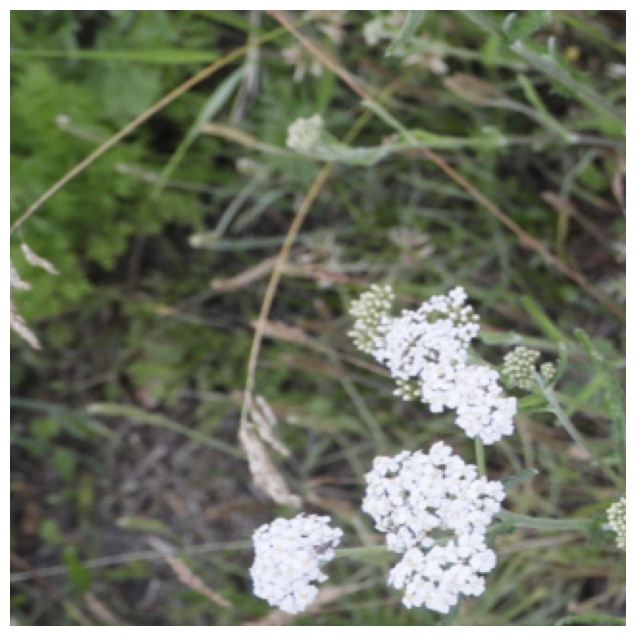

In [8]:

import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

#eerste afbeelding uit testdataset
#image, target = datamodule.test_data[0]
image, target = datamodule.test_dataloader().dataset[0]

# model in evaluatiemodus
model.eval()

#model voorspelingen maken
with torch.inference_mode():
    prediction = model.model([image])[0]

#  afbeelding toonen
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image.permute(1, 2, 0))

#voorspellingen met minimaal 30% zekerheid
threshold = 0.30

for box, label, score in zip(
    prediction["boxes"],
    prediction["labels"],
    prediction["scores"]
):
    if score.item() < threshold:
        continue

    xmin, ymin, xmax, ymax = box.tolist()
    bloemsoort = dataset.classes[label.item()]

    ax.add_patch(Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="magenta",
        linewidth=2
    ))

    ax.text(
        xmin, ymin,
        f"{bloemsoort}: {score.item():.1%}",
        color="white",
        bbox=dict(facecolor="purple", alpha=0.8)
    )

ax.axis("off")
plt.show()


In [9]:
print("Aantal voorspellingen:", len(prediction["scores"]))

print("\nDe 10 hoogste scores:")
for score, label in zip(
    prediction["scores"][:10],
    prediction["labels"][:10]
):
    print(
        dataset.classes[label.item()],
        f"{score.item():.2%}"
    )

Aantal voorspellingen: 0

De 10 hoogste scores:


## Experiment 2 - Uitgebreidere CPU-training

Instellingen:
- 5 epochs
- 30 trainingsbatches per epoch
- Afbeeldingen: 320 × 320 pixels

Resultaat:
- Training succesvol afgerond.
- Laatste epoch: ongeveer 14 seconden.
- Aantal gedetecteerde objecten: nog te bepalen.

In [10]:
#nagaan of meer training zorgt dat het model bloemen begint te detecteren
#terugzetten naar trainingsmodus
model.train()
trainer2 = Trainer(
    accelerator="cpu",
    devices=1,
    max_epochs=5,
    limit_train_batches=30,
    limit_val_batches=2,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True
)

trainer2.fit(model, datamodule=datamodule)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                 | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model | FasterRCNN           | 19.0 M | train | 0    
1 | mAP   | MeanAveragePrecision | 0      | train | 0    
---------------------------------------------------------------
18.9 M    Trainable params
58.9 K    Non-trainable params
19.0 M    Total params
75.905    Total estimated model params size (MB)
281       Modules in train mode
0         Modules in eval mode
0         Total Flops


Epoch 4: 100%|██████████| 30/30 [00:14<00:00,  2.06it/s]                   

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 30/30 [00:14<00:00,  2.06it/s]


In [11]:
import torch

torch.save(model.state_dict(), "wildflower_model.pth")

print("Model opgeslagen!")

Model opgeslagen!


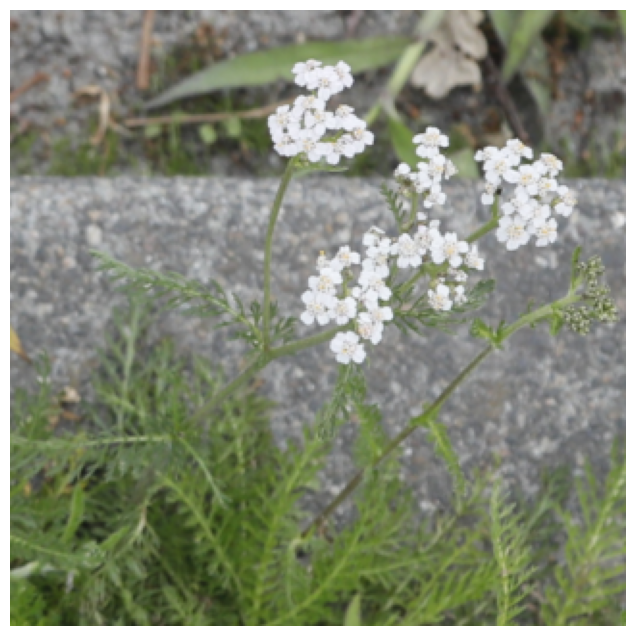

In [12]:
#Experiment 2 Objectdetectie na 5 epochs
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

#eerste afbeelding uit testdataset
#image, target = datamodule.test_data[0]
image, target = datamodule.test_dataloader().dataset[0]

# model in evaluatiemodus
model.eval()

#model voorspelingen maken
with torch.inference_mode():
    prediction = model.model([image])[0]

#  afbeelding toonen
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image.permute(1, 2, 0))

#voorspellingen met minimaal 30% zekerheid
threshold = 0.30

for box, label, score in zip(
    prediction["boxes"],
    prediction["labels"],
    prediction["scores"]
):
    if score.item() < threshold:
        continue

    xmin, ymin, xmax, ymax = box.tolist()
    bloemsoort = dataset.classes[label.item()]

    ax.add_patch(Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="magenta",
        linewidth=2
    ))

    ax.text(
        xmin, ymin,
        f"{bloemsoort}: {score.item():.1%}",
        color="white",
        bbox=dict(facecolor="purple", alpha=0.8)
    )

ax.axis("off")
plt.show()

In [13]:
print("Aantal voorspellingen:", len(prediction["scores"]))

print("\nDe 10 hoogste scores:")
for score, label in zip(
    prediction["scores"][:10],
    prediction["labels"][:10]
):
    print(
        dataset.classes[label.item()],
        f"{score.item():.2%}"
    )

Aantal voorspellingen: 0

De 10 hoogste scores:


In [ ]:

# Experiment 2 Onderzoek naar ontbrekende voorspellingen

# Huidige interne drempel bekijken
print("Oorspronkelijke drempel:",
      model.model.roi_heads.score_thresh)

# Interne drempel tijdelijk verlagen
model.model.roi_heads.score_thresh = 0.0

# Opnieuw voorspellen
model.eval()

with torch.inference_mode():
    prediction = model.model([image])[0]

print("Aantal voorspellingen:",
      len(prediction["scores"]))

print("\nDe 10 hoogste scores:")
for score, label in zip(
    prediction["scores"][:10],
    prediction["labels"][:10]
):
    print(
        dataset.classes[label.item()],
        f"{score.item():.2%}"
    )


Oorspronkelijke drempel: 0.05
Aantal voorspellingen: 0

De 10 hoogste scores:


In [15]:

# Experiment 2  Controle van testdata

image, target = datamodule.test_dataloader().dataset[0]

print("Afbeeldingsgrootte:", image.shape)
print("Bounding boxes:", target["boxes"])
print("Labels:", target["labels"])

print("\nBloemsoorten:")
for label in target["labels"]:
    print(dataset.classes[label.item()])

print("\nAantal annotaties:", len(target["boxes"]))


Afbeeldingsgrootte: torch.Size([3, 320, 320])
Bounding boxes: tensor([[131.5625,  23.4375, 297.8125, 186.2500]])
Labels: tensor([1])

Bloemsoorten:
Achillea millefolium

Aantal annotaties: 1


In [16]:

# Experiment 2  Controle van Region Proposals

model.eval()

with torch.inference_mode():
    # Afbeelding voorbereiden voor Faster R-CNN
    images, _ = model.model.transform([image], None)

    # Kenmerken uit de afbeelding halen
    features = model.model.backbone(images.tensors)

    # Kandidaatgebieden laten zoeken
    proposals, _ = model.model.rpn(
        images, features, None
    )

print("Aantal kandidaatgebieden:", len(proposals[0]))

print("\nEerste 5 kandidaatgebieden:")
print(proposals[0][:5])


Aantal kandidaatgebieden: 0

Eerste 5 kandidaatgebieden:
tensor([], size=(0, 4))


In [17]:

# Experiment 2 Controle RPN-instellingen

rpn = model.model.rpn

print("Score threshold:", rpn.score_thresh)
print("NMS threshold:", rpn.nms_thresh)
print("Minimale boxgrootte:", rpn.min_size)
print("Post-NMS top N:", rpn.post_nms_top_n())
print("Pre-NMS top N:", rpn.pre_nms_top_n())


Score threshold: 0.05
NMS threshold: 0.7
Minimale boxgrootte: 0.001
Post-NMS top N: 150
Pre-NMS top N: 150


In [18]:

# Experiment 2 RPN-scoregrens onderzoeken

rpn = model.model.rpn

# Oorspronkelijke instelling bewaren
oude_drempel = rpn.score_thresh

# Tijdelijk alle scores toestaan
rpn.score_thresh = 0.0

model.eval()

with torch.inference_mode():
    images, _ = model.model.transform([image], None)
    features = model.model.backbone(images.tensors)
    proposals, _ = rpn(images, features, None)

print("Aantal kandidaatgebieden:", len(proposals[0]))
print("\nEerste 5 kandidaatgebieden:")
print(proposals[0][:5])

# Oorspronkelijke instelling herstellen
rpn.score_thresh = oude_drempel


Aantal kandidaatgebieden: 0

Eerste 5 kandidaatgebieden:
tensor([], size=(0, 4))


In [19]:

# Experiment 2 Controle op ongeldige modelparameters

import torch

ongeldige_parameters = []

for naam, parameter in model.model.named_parameters():
    if not torch.isfinite(parameter).all():
        ongeldige_parameters.append(naam)

print("Aantal parameters met ongeldige waarden:",
      len(ongeldige_parameters))

if ongeldige_parameters:
    print("\nParameters met NaN of Inf:")
    for naam in ongeldige_parameters[:10]:
        print(naam)
else:
    print("Alle modelparameters bevatten geldige getallen.")


Aantal parameters met ongeldige waarden: 65

Parameters met NaN of Inf:
backbone.body.7.block.0.0.weight
backbone.body.7.block.1.0.weight
backbone.body.7.block.2.0.weight
backbone.body.8.block.0.0.weight
backbone.body.8.block.1.0.weight
backbone.body.8.block.2.0.weight
backbone.body.9.block.0.0.weight
backbone.body.9.block.1.0.weight
backbone.body.9.block.2.0.weight
backbone.body.10.block.0.0.weight


## Experiment 3  Training met lagere learning rate

Doel:
Onderzoeken of een lagere learning rate voorkomt dat
ongeldige modelparameters (NaN of Inf) ontstaan.

Instellingen:
- Model: Faster R-CNN MobileNetV3
- Afbeeldingsgrootte: 320 × 320
- Learning rate: 0.001
- Epochs: 5
- Maximaal 30 trainingsbatches per epoch
- Hardware: CPU

In [20]:

# Experiment 3 Nieuw model aanmaken

pretrained_model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn(
    weights="DEFAULT"
)

model3 = ObjectDetectionModel(
    pretrained_model,
    num_classes=len(dataset.classes)
)

print("nieuw model voor experiment 3 aangemaakt.")


nieuw model voor experiment 3 aangemaakt.


In [21]:

# Experiment 3 Learning rate aanpassen

def optimizer_experiment3():
    optimizer = torch.optim.SGD(
        model3.parameters(),
        lr=0.001,
        momentum=0.9,
        weight_decay=0.0005
    )

    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=5,
        gamma=0.1
    )

    return {
        "optimizer": optimizer,
        "lr_scheduler": scheduler
    }

# Alleen voor model3 de optimizer vervangen
model3.configure_optimizers = optimizer_experiment3

print("Learning rate experiment 3: 0.001")


Learning rate experiment 3: 0.001


In [22]:

# Experiment 3 Training op CPU

trainer3 = Trainer(
    accelerator="cpu",
    devices=1,
    max_epochs=5,
    limit_train_batches=30,
    limit_val_batches=2,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True
)

trainer3.fit(model3, datamodule=datamodule)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name  | Type                 | Params | Mode  | FLOPs
---------------------------------------------------------------
0 | model | FasterRCNN           | 19.0 M | train | 0    
1 | mAP   | MeanAveragePrecision | 0      | train | 0    
---------------------------------------------------------------
18.9 M    Trainable params
58.9 K    Non-trainable params
19.0 M    Total params
75.905    Total estimated model params size (MB)
281       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


c:\Users\beheerder\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Epoch 4: 100%|██████████| 30/30 [00:22<00:00,  1.35it/s]

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 30/30 [00:22<00:00,  1.35it/s]


In [23]:

# Experiment 3 Controle modelparameters

ongeldige_parameters = []

for naam, parameter in model3.model.named_parameters():
    if not torch.isfinite(parameter).all():
        ongeldige_parameters.append(naam)

print("Aantal parameters met NaN of Inf:",
      len(ongeldige_parameters))

if len(ongeldige_parameters) == 0:
    print("Alle modelparameters zijn geldig.")
else:
    print("Er zijn nog ongeldige modelparameters.")
    print(ongeldige_parameters[:10])


Aantal parameters met NaN of Inf: 0
Alle modelparameters zijn geldig.


Aantal voorspellingen: 3


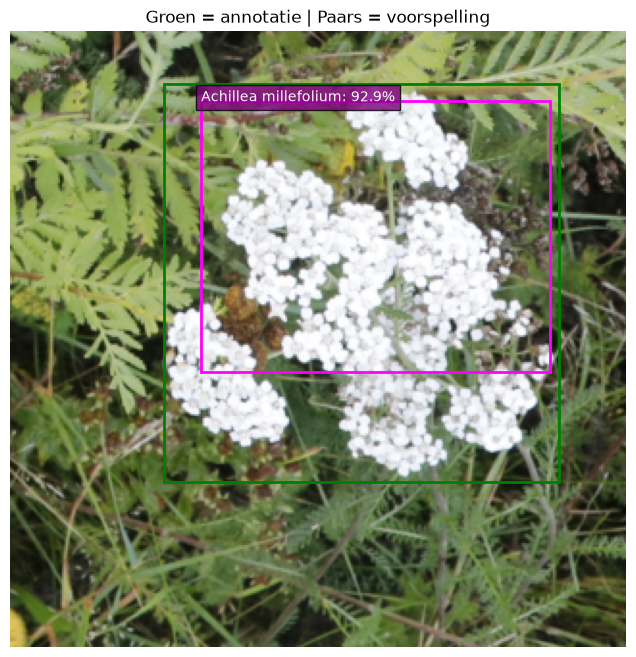

In [24]:

# Experiment 3 objectdetectietest

import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Dezelfde eerste testafbeelding gebruiken
image, target = datamodule.test_dataloader().dataset[0]

# Model 3 in evaluatiemodus
model3.eval()

with torch.inference_mode():
    prediction3 = model3.model([image])[0]

print("Aantal voorspellingen:",
      len(prediction3["scores"]))

# Afbeelding tonen
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image.permute(1, 2, 0))

# Echte bounding box uit XML: groen
for box in target["boxes"]:
    xmin, ymin, xmax, ymax = box.tolist()

    ax.add_patch(Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="green",
        linewidth=2
    ))

# Voorspellingen model: paars
for box, label, score in zip(
    prediction3["boxes"],
    prediction3["labels"],
    prediction3["scores"]
):
    if score.item() < 0.30:
        continue

    xmin, ymin, xmax, ymax = box.tolist()

    ax.add_patch(Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="magenta",
        linewidth=2
    ))

    ax.text(
        xmin, ymin,
        f"{dataset.classes[label.item()]}: {score.item():.1%}",
        color="white",
        bbox=dict(facecolor="purple", alpha=0.8)
    )

ax.set_title("Groen = annotatie | Paars = voorspelling")
ax.axis("off")
plt.show()


Totale mAP: 0.358
mAP@50: 0.65


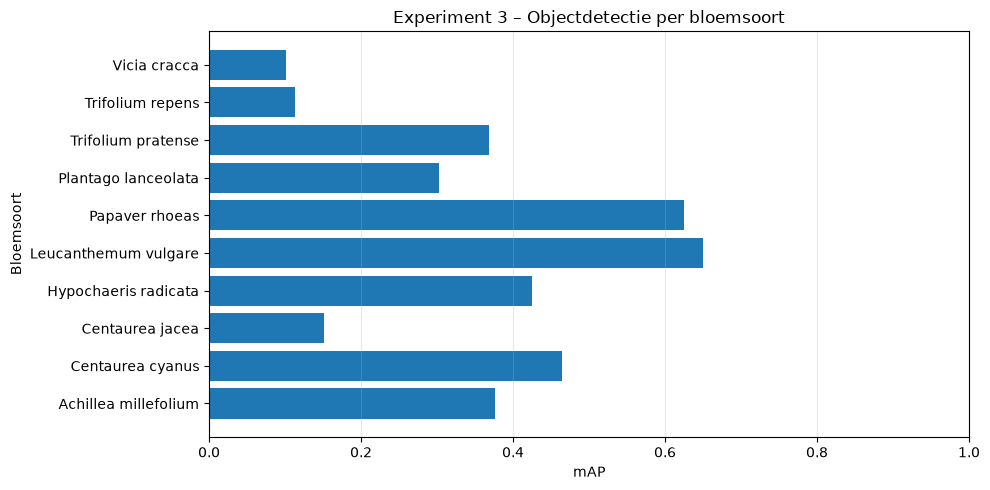

In [25]:

# Experiment 3 mAP per bloemsoort op de testdataset

import torch
import matplotlib.pyplot as plt
from torchmetrics.detection.mean_ap import MeanAveragePrecision

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True
)

model3.eval()

# Alle testafbeeldingen beoordelen
with torch.inference_mode():
    for images, targets in datamodule.test_dataloader():
        predictions = model3.model(list(images))
        metric.update(predictions, list(targets))

resultaten = metric.compute()

print("Totale mAP:", round(resultaten["map"].item(), 3))
print("mAP@50:", round(resultaten["map_50"].item(), 3))

# Resultaten per bloemsoort
klassen = resultaten["classes"].tolist()
scores = resultaten["map_per_class"].tolist()

namen = [dataset.classes[int(k)] for k in klassen]

# -1 geen geldige mAP voor deze klasse
geldige_scores = [
    max(0, score) for score in scores
]

plt.figure(figsize=(10, 5))
plt.barh(namen, geldige_scores)
plt.xlabel("mAP")
plt.ylabel("Bloemsoort")
plt.title("Experiment 3 – Objectdetectie per bloemsoort")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
torch.save(model3.state_dict(), "wildflower_model_exp3.pth")
print("Model opgeslagen")

In [ ]:
metrics = pandas.read_csv(os.path.join(trainer.log_dir, "metrics.csv"))
loss_metrics = metrics[["epoch", "val_mAP"]].set_index("epoch")
plot = loss_metrics.plot()

In [ ]:
scores = trainer.test(model, datamodule=datamodule, verbose=False)
mAPs = [scores[0]["test_mAP_class_" + str(i+1)] for i in range(len(dataset.classes)-1)]
df = pandas.DataFrame({"class": dataset.classes[1:], "mAP": mAPs}).set_index("class")
df

# 🔬 Evaluation

In [ ]:
dataloader = datamodule.test_dataloader()
preds = trainer.predict(model, dataloaders=dataloader)
preds = [a for b in preds for a in b]

images = [d[0] for _, d in enumerate(dataloader.dataset)]
targets = [d[1] for _, d in enumerate(dataloader.dataset)]


In [ ]:
threshold = .7
fig, axes = plt.subplots(20, 3, figsize=(15, 100))
axes = axes.flatten()
for ax, image, prediction, target in zip(axes, images, preds, targets):
    ax.imshow(torchvision.transforms.ToPILImage()(image))
    ax.axis("off")
    for truth, label in zip(target["boxes"], target["labels"]):
        xmin, ymin, xmax, ymax = truth[0], truth[1], truth[2], truth[3]
        rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color='lightgray', linewidth=1)
        ax.add_patch(rect)
        ax.text(xmin, ymin - 5, dataset.classes[label.item()], color='lightgray', fontsize=11)
    for box, label, score in zip(prediction["boxes"], prediction["labels"], prediction["scores"]):
        if score < threshold:
            continue
        xmin, ymin, xmax, ymax = box
        rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color='fuchsia', linewidth=1)
        ax.add_patch(rect)
        ax.text(xmin, ymax + 40, dataset.classes[label.item()] + " " + str(round(score.item(),2)), color='fuchsia', fontsize=11)


# 🚀 Inference

Now let's try this on one of the inference images that the model did not see during training. Note that the inference images are way larger than the image size we used to train the model on (and in the original dataset they are even larger than the inference images provided here). so we need to make tiles of these images an run inference per tile. First it shows the full image, and then the tiles with predictions on them. 

Feel free to try any of the other inference images, or maybe an image that you took yourself outside.

In [ ]:
# inference_image = "inference/20210605141844-Cropland.jpg"
inference_image = "inference/20220528102624-Roadside.jpg"
# inference_image = "inference/20220702201330-Roadside.jpg"
IPython.display.Image(inference_image)

In [ ]:
def tile_image(path, tile_size=(640, 640)):
    img = PIL.Image.open(path).convert("RGB")
    width, height = img.size
    tile_w, tile_h = tile_size
    if width % tile_w != 0 or height % tile_h != 0:
        raise ValueError(f"Image size {width}x{height} is not divisible by tile size {tile_w}x{tile_h}.")
    tiles = []
    for y in range(0, height, tile_h):
        for x in range(0, width, tile_w):
            box = (x, y, x + tile_w, y + tile_h)
            image = transforms.ToTensor()(img.crop(box))
            tiles.append(image)
    return tiles

tiles = tile_image(inference_image)
batch = torch.stack(tiles, dim=0).to(torch.float32)
labels = torch.full((len(tiles),), 0, dtype=torch.float32)
inference_loader = DataLoader(TensorDataset(batch,labels), batch_size=len(tiles), shuffle=False)
preds = trainer.predict(model, dataloaders=inference_loader)[0]
images = [d[0] for _, d in enumerate(inference_loader.dataset)]

threshold = .5
fig, axes = plt.subplots(4, 6, figsize=(30, 20))
axes = axes.flatten()
for ax, image, prediction in zip(axes, images, preds):
    ax.imshow(torchvision.transforms.ToPILImage()(image))
    ax.axis("off")
    for box, label, score in zip(prediction["boxes"], prediction["labels"], prediction["scores"]):
        if score < threshold:
            continue
        xmin, ymin, xmax, ymax = box
        rect = plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color='fuchsia', linewidth=1)
        ax.add_patch(rect)
        ax.text(xmin, ymax + 40, dataset.classes[label.item()] + " " + str(round(score.item(),2)), color='fuchsia', fontsize=10)